# 01 - Project: Sublime Limes' Line Graphs
*Codecademy: Analyze Financial Data with Python / Visualizing Finance Data*

We are a data analyst for **Sublime Limes**, an online lime retailer. A product manager wants to understand the customers and their buying habits, so we build two line graphs in one figure:
- **left:** website visits per month over the past year
- **right:** how many limes of each species were sold per month

Uses everything from [01_matplotlib_basics](01_matplotlib_basics.ipynb): subplots, `ax`, markers, colours, ticks, legends, `subplots_adjust` and `savefig`.

In [1]:
from matplotlib import pyplot as plt

CHARTS = 'charts/'

**Tasks 1-2**
- Task 1: add `import codecademylib` to the top of script.py (Codecademy-only - not needed locally)
- Task 2: look through the provided lists and work out what each one represents

We look at the data first. One list of month names, one list of visits, and three lists of limes sold - one per species. Every list has 12 values, one per month.

In [2]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

visits_per_month = [9695, 7909, 10831, 12942, 12495, 16794, 14161, 12762, 12777, 12439, 10309, 8724]

# numbers of limes of different species sold each month
key_limes_per_month = [92.0, 109.0, 124.0, 70.0, 101.0, 79.0, 106.0, 101.0, 103.0, 90.0, 102.0, 106.0]
persian_limes_per_month = [67.0, 51.0, 57.0, 54.0, 83.0, 90.0, 52.0, 63.0, 51.0, 44.0, 64.0, 78.0]
blood_limes_per_month = [75.0, 75.0, 76.0, 71.0, 74.0, 77.0, 69.0, 80.0, 63.0, 69.0, 73.0, 82.0]

**Tasks 3-4, 6-11 - figure and left subplot (page visits over time)**
- Task 3: create a figure of width 12 and height 8
- Task 4: create the left subplot of a 1 row x 2 columns layout, save it as `ax1`
- Task 6: create `x_values = range(len(months))` - after `ax1`, before `ax2`
- Task 7: plot the total page visits against `x_values` as a line
- Task 8: give the line markers, so each month shows as a distinct value
- Task 9: label the x- and y-axis with descriptive titles
- Task 10: set the x-ticks to `x_values`
- Task 11: set the x-tick labels to the `months` list

We create a figure of 12 x 8 inches and the left subplot. The month names are text, so we plot against numbers `0-11` and swap in the names as tick labels later.

```text
plt.subplot(1, 2, 1)     1 row, 2 columns, box 1  -> LEFT
plt.subplot(1, 2, 2)     1 row, 2 columns, box 2  -> RIGHT

+-----------+-----------+
|   ax1     |   ax2     |
|  visits   |  limes    |
+-----------+-----------+

range(len(months))  ->  len = 12  ->  range(12) = 0, 1, ... 11
```

`ax1 = plt.subplot(...)` does two things at once: selects the left box **and** keeps it in a variable, so later we can say exactly which chart a command is for.

We plot the visits on the left, with markers so every month shows as its own point, and set the labels and ticks.

Text(0.5, 1.0, 'Visitors each month')

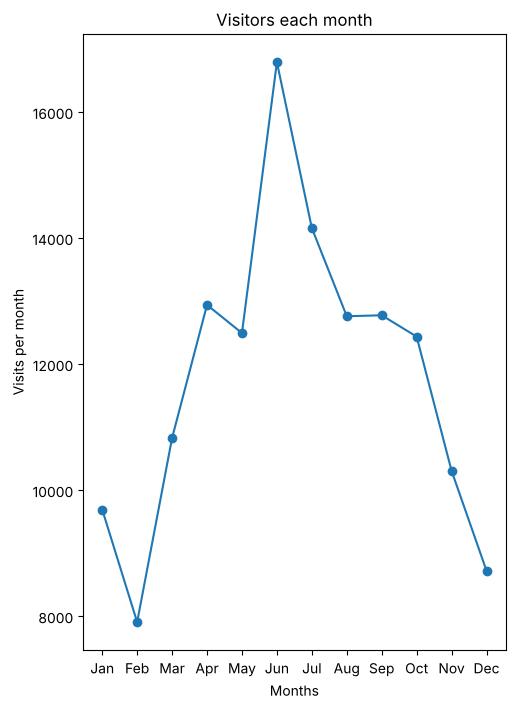

In [3]:
fig = plt.figure(figsize=(12, 8))

ax1 = plt.subplot(1, 2, 1)
x_values = range(len(months))

ax1.plot(x_values, visits_per_month, marker='o')
ax1.set_xlabel('Months')
ax1.set_ylabel('Visits per month')
ax1.set_xticks(x_values)
ax1.set_xticklabels(months)
ax1.set_title('Visitors each month')

**Tasks 5, 12-13, 15 - right subplot (multiple lime species)**
- Task 5: create the right subplot, save it as `ax2`
- Task 12: on one plot, draw key limes, Persian limes and blood limes sold vs `x_values`
- Task 13: give each line a specific colour of your choosing
- Task 15: set the x-ticks to `x_values` and the tick labels to `months`

We create the right subplot and plot the three lime species on the same axes, each in its own colour.

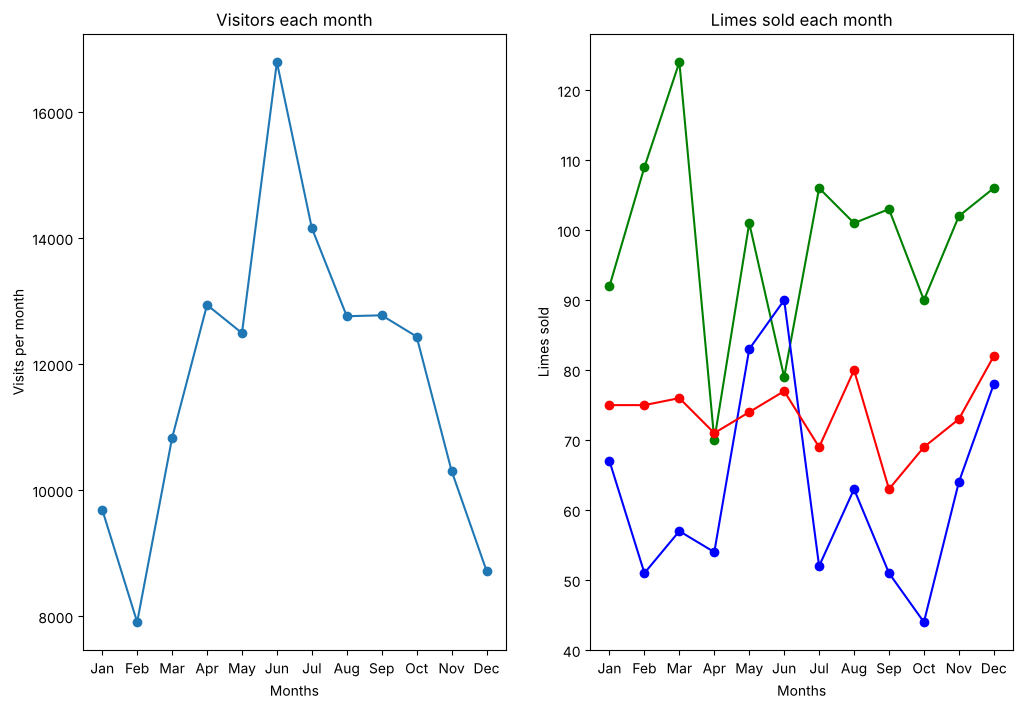

In [4]:
ax2 = fig.add_subplot(1, 2, 2)

ax2.plot(x_values, key_limes_per_month, marker='o', color='green')
ax2.plot(x_values, persian_limes_per_month, marker='o', color='blue')
ax2.plot(x_values, blood_limes_per_month, marker='o', color='red')
ax2.set_xlabel('Months')
ax2.set_ylabel('Limes sold')
ax2.set_xticks(x_values)
ax2.set_xticklabels(months)
ax2.set_title('Limes sold each month')
fig

**Why `fig.add_subplot` instead of `plt.subplot` here?** In a notebook the "current figure" is cleared at the end of every cell - the sheet leaves the desk (section 11 of the basics). A `plt.subplot(1, 2, 2)` in a *new* cell would start a **new, separate** figure. `fig.add_subplot(1, 2, 2)` says *which* figure to add the box to, so it lands next to `ax1`. Same for `fig.subplots_adjust` below. In one single cell or a `.py` script, `plt.subplot` works exactly the same.

**Order matters:** everything for the left chart comes after `ax1 = ...` and before `ax2 = ...`. Because every command starts with `ax1.` or `ax2.`, it's always clear which box it goes into - even if we wrote them in a different order.

**Task 14**
- Task 14: add a legend that labels each lime species

We add a legend and let matplotlib find the emptiest spot for it.

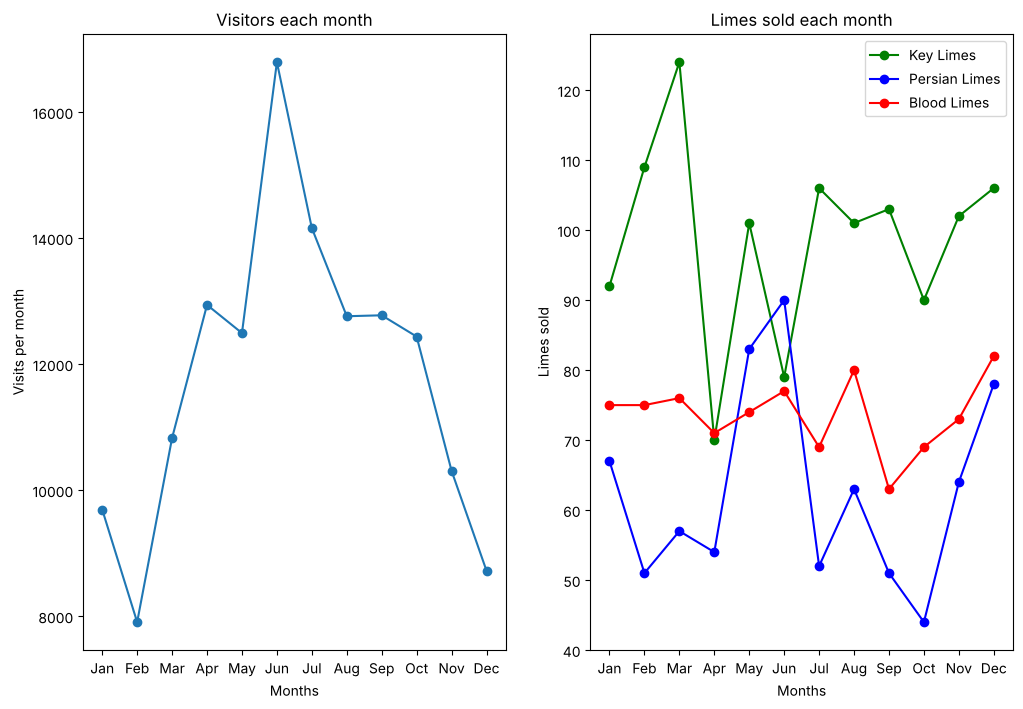

In [5]:
legend_labels = ['Key Limes', 'Persian Limes', 'Blood Limes']
ax2.legend(legend_labels, loc='best')
fig

`loc='best'` (= `loc=0`, the default) checks where the legend covers the fewest data points - here the empty top right corner.

**Tasks 16-17 - labeling and saving**
- Task 16: add a title to each plot, and adjust the margins so the text looks better *(the titles are already set in the two cells above)*
- Task 17: save the figure as a png with a descriptive file name

Finally we give the two charts more space between them, then save and show.

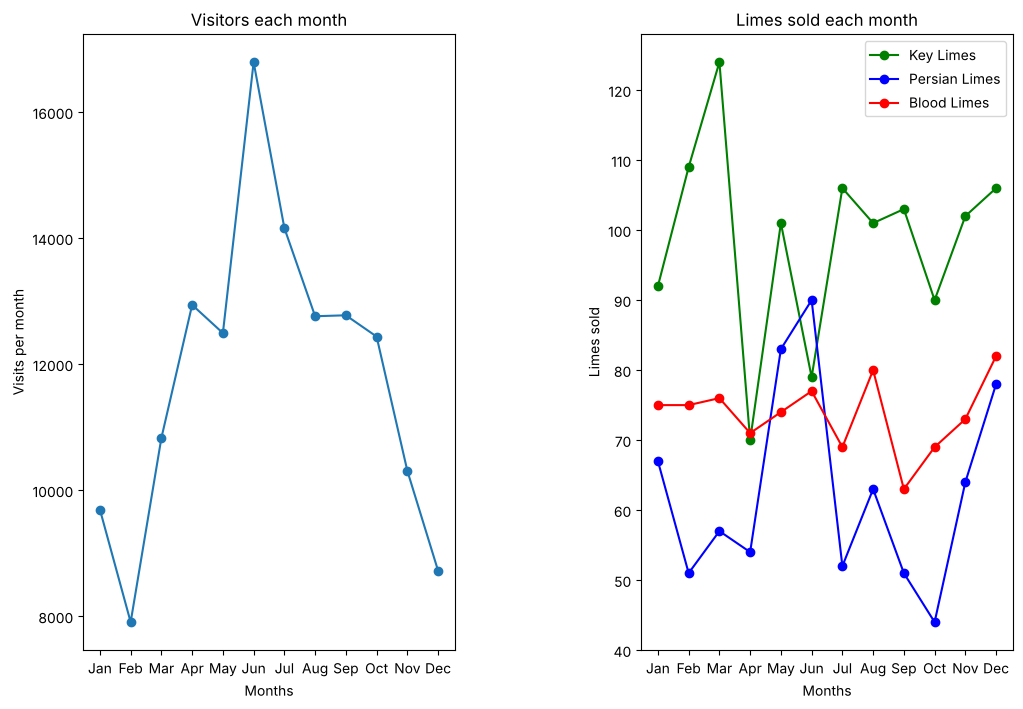

In [6]:
fig.subplots_adjust(wspace=0.5)
fig.savefig(CHARTS + 'sublime_limes_visits_and_sales.png')
fig

**Adjust -> save -> show, in that order.** `savefig` takes a snapshot of the figure at that moment - anything changed afterwards only shows on screen, not in the file.

```text
fig.subplots_adjust(wspace=0.5)   1. adjust   <- layout is final
fig.savefig('...png')             2. save     <- snapshot of the final layout
fig / plt.show()                  3. show
```

### What the charts show
- **Visits** peak in **June** (~16,800) and are lowest in **February** (~7,900) - a clear summer season.
- **Key limes** are the best seller almost every month, but jump around a lot (70 in April, 124 in March).
- **Blood limes** are the steadiest - always between 63 and 82.
- **Persian limes** spike in May-June together with the visits, then drop.
- Lime sales **don't** simply follow the visits: June has the most visitors, but key lime sales dip that month.